# Étape 3 — Analyse complète des résultats (Régression, Cas 1)
**Version enrichie de `03_analyseReg.ipynb`** — ajoute la sélection de variables par stabilité.

**Prérequis** : avoir exécuté `02_Reg_pipeline_complet.ipynb`, qui compare tous les modèles (MCO → boosting) en validation croisée et écrit les prédictions dans `PREV_complet.csv`.

**Ce notebook** :
- Calcule MSE / RMSE / MAE par méthode
- Visualise les résidus (boxplot)
- Analyse la stabilité des λ Lasso
- Identifie les **variables robustes** par sélection bootstrap (Lasso + ElasticNet)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV, ElasticNetCV, RidgeCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
import os

# ← Modifier si les fichiers sont ailleurs
DOSSIER_PREV    = "../FICHIERS FINAUX/"
DOSSIER_DONNEES = "../FICHIERS FINAUX/DONNEES/"
# DONNEES   = DOSSIER_DONNEES + "ozone_transf.txt"
DONNEES = pd.read_csv("https://regression-avec-python.github.io/donnees/ozone_transf.txt", header=0, sep=";", index_col=0)
DONNEES.rename(columns={"maxO3": "Y"}, inplace=True)

GRAINE = 42
kf = KFold(n_splits=10, shuffle=True, random_state=GRAINE)

## 1. Chargement de PREV_complet.csv

In [2]:
FICHIER_PREV = "PREV_complet.csv"   # "PREV_complet.csv" : 02_Reg_pipeline_complet (validation croisee) ; "PREV_test.csv" : 02_Reg_pipeline_split (echantillon de test) ; "PREV_cvtest.csv" : 02_Reg_pipeline_complet avec TAILLE_TEST_FINAL > 0 (test final)
chemin_prev = DOSSIER_PREV + FICHIER_PREV

if not os.path.exists(chemin_prev):
    raise FileNotFoundError(
        f"{chemin_prev} introuvable.\n"
        "Etapes :\n"
        "  1. Ouvrir FICHIERS FINAUX/02_Reg_pipeline_complet.ipynb\n"
        "  2. Executer toutes les cellules (il ecrit PREV_complet.csv)"
    )

PREV = pd.read_csv(chemin_prev)
print(f"PREV charge : {PREV.shape[0]} observations x {PREV.shape[1]} colonnes")
print(f"Methodes disponibles : {list(PREV.columns[2:])}")
print(f"Blocs CV : {PREV['bloc'].nunique()}")
PREV.head(3)

PREV charge : 1366 observations x 17 colonnes
Methodes disponibles : ['MCO', 'BIC', 'AIC', 'lasso', 'elastic', 'ridge', 'ridgeGS', 'foret', 'pcr', 'pls', 'gbm1', 'gbm2', 'gbms1', 'gbms2', 'cat']
Blocs CV : 10


,bloc,Y,MCO,BIC,AIC,lasso,elastic,ridge,ridgeGS,foret,pcr,pls,gbm1,gbm2,gbms1,gbms2,cat
0,2,47.6,57.494473,60.258405,58.115172,59.334502,57.759069,57.692647,57.671315,59.676,57.621366,57.482855,59.779295,59.292356,62.518234,60.758269,62.815229
1,3,56.2,62.899981,57.466640,60.605343,61.650229,62.704213,62.907366,62.907366,55.452,61.235650,62.709865,67.372460,65.937820,68.113038,63.964853,64.289851
2,8,61.8,85.985247,86.206486,84.296830,84.488402,85.452462,85.738667,85.751965,74.272,87.657690,85.988956,77.252511,79.514312,76.391465,80.277333,79.691827


## 2. Métriques par méthode

In [3]:
methodes = [c for c in PREV.columns if c not in ["bloc", "Y"]]      # récupération des prédictions des différents modèles
residus  = PREV[methodes].sub(PREV["Y"], axis=0)                    # pour chaque modèle : residu = Yprev - Y

metriques = pd.DataFrame(index=methodes)
metriques["MSE"]      = (residus ** 2).mean().round(2)              # MSE	Moyenne des erreurs²	Pénalise fortement les grandes erreurs
metriques["RMSE"]     = np.sqrt((residus ** 2).mean()).round(3)     # RMSE	√MSE	Même unité que Y → plus interprétable
metriques["MAE"]      = residus.abs().mean().round(2)               # MAE	Moyenne des |erreurs|	Plus robuste aux outliers que le MSE

# tri des MSE par ordre croissant (donc du meilleur modèle au moins bon)
metriques["Rang_MSE"] = metriques["MSE"].rank().astype(int)
metriques_tries = metriques.sort_values("MSE")

print("Comparaison des methodes (MSE croissante) :")
print(metriques_tries.to_string())

Comparaison des methodes (MSE croissante) :
            MSE    RMSE    MAE  Rang_MSE
cat      154.87  12.445   9.47         1
foret    155.28  12.461   9.55         2
gbm2     156.31  12.502   9.67         3
gbm1     160.72  12.678   9.86         4
gbms2    162.70  12.755   9.82         5
gbms1    165.14  12.851  10.01         6
lasso    187.05  13.677  10.78         7
elastic  187.20  13.682  10.78         8
ridgeGS  187.43  13.690  10.80         9
ridge    187.45  13.691  10.80        10
MCO      187.51  13.694  10.80        11
AIC      187.74  13.702  10.79        12
pls      187.92  13.709  10.82        13
pcr      188.22  13.719  10.81        14
BIC      188.23  13.720  10.80        15


## 3. Visualisation des erreurs

/tmp/ipykernel_11306/3367803080.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot(residus_grouped, labels=methodes_triees, vert=False)


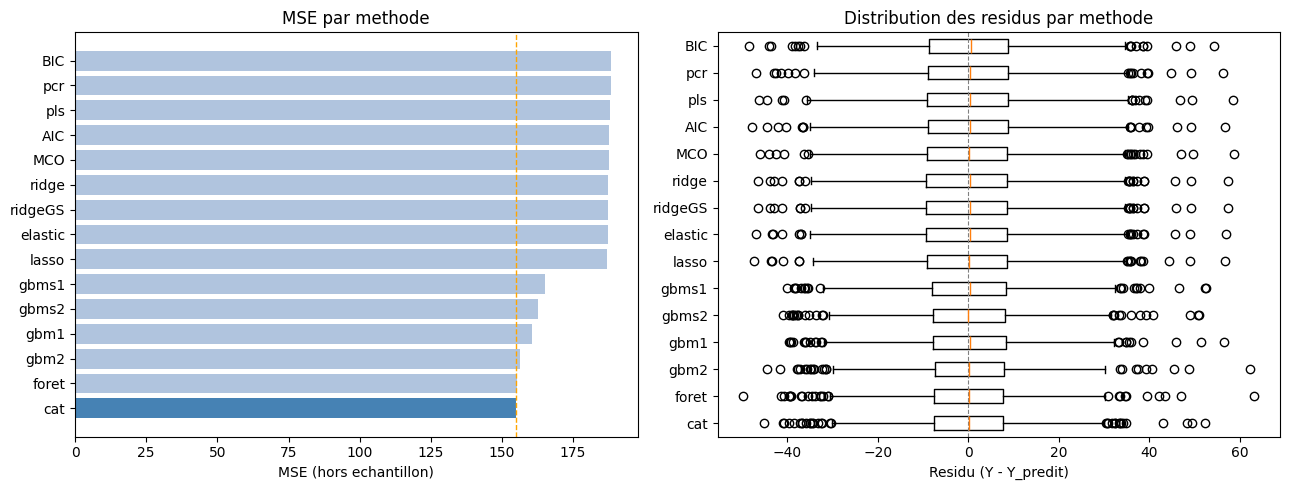

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

m = metriques_tries
colors = ["steelblue" if mse == m.MSE.min() else "lightsteelblue" for mse in m.MSE]
ax1.barh(m.index, m.MSE, color=colors)
ax1.set_xlabel("MSE (hors echantillon)")
ax1.set_title("MSE par methode")
ax1.axvline(x=m.MSE.min(), color="orange", linestyle="--", linewidth=1)

methodes_triees = metriques_tries.index.tolist()
residus_grouped = [residus[m_].values for m_ in methodes_triees]
ax2.boxplot(residus_grouped, labels=methodes_triees, vert=False)
ax2.set_xlabel("Residu (Y - Y_predit)")
ax2.set_title("Distribution des residus par methode")
ax2.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.show()

---
## 4. Sélection par stabilité (bootstrap Lasso + ElasticNet)
**Principe** (Meinshausen & Bühlmann, 2010) : on tire `N_BOOT` échantillons bootstrap, on fitte le Lasso (et l'ElasticNet) sur chacun, et on mesure la **fréquence de sélection** de chaque variable.

- Variable sélectionnée dans **> 50 %** des bootstraps → **robuste**
- Variable sélectionnée rarement → artefact, dépend de l'échantillon

**Pourquoi Lasso et ElasticNet seulement ?**
- Lasso et ElasticNet produisent des coefficients exactement nuls → sélection binaire → comptage naturel
- Ridge : conserve toutes les variables (aucun coeff = 0) → fréquence toujours 100 % → inutile
- MCO : idem Ridge
- Forêt : pas de sélection binaire → approche différente (variance des importances)

In [5]:
don = DONNEES

Y_imp   = don["Y"].values
X_df    = don.drop(columns=["Y"]).select_dtypes(include=[np.number])
nomsvar = list(X_df.columns)
X_imp   = X_df.values
print(f"{len(nomsvar)} variables : {nomsvar}")
print(f"{len(Y_imp)} observations")

21 variables : ['T6', 'T9', 'T12', 'T15', 'T18', 'Ne6', 'Ne9', 'Ne12', 'Ne15', 'Ne18', 'Vx6', 'Vy6', 'Vx9', 'Vy9', 'Vx12', 'Vy12', 'Vx15', 'Vy15', 'Vx18', 'Vy18', 'maxO3v']
1366 observations


In [6]:
from sklearn.utils import resample

N_BOOT = 100
counts_lasso = pd.Series(0, index=nomsvar)
counts_enet  = pd.Series(0, index=nomsvar)
rng_boot = np.random.default_rng(GRAINE)

for b in range(N_BOOT):
    seed_b = int(rng_boot.integers(0, 99999))
    X_boot, Y_boot = resample(X_imp, Y_imp, random_state=seed_b)

    # Lasso
    pipe_l = Pipeline([("scaler", StandardScaler()),
                       ("lasso",  LassoCV(cv=5, max_iter=5000, random_state=seed_b))])
    pipe_l.fit(X_boot, Y_boot)
    counts_lasso += (pipe_l.named_steps["lasso"].coef_ != 0).astype(int)

    # ElasticNet
    pipe_e = Pipeline([("scaler", StandardScaler()),
                       ("enet",   ElasticNetCV(cv=5, max_iter=5000, random_state=seed_b))])
    pipe_e.fit(X_boot, Y_boot)
    counts_enet += (pipe_e.named_steps["enet"].coef_ != 0).astype(int)

freq_lasso = (counts_lasso / N_BOOT).sort_values(ascending=False)
freq_enet  = (counts_enet  / N_BOOT).sort_values(ascending=False)

print(f"Frequence de selection — bootstrap Lasso ({N_BOOT} repetitions) :")
print(freq_lasso.round(3).to_string())
print(f"\nFrequence de selection — bootstrap ElasticNet ({N_BOOT} repetitions) :")
print(freq_enet.round(3).to_string())

Frequence de selection — bootstrap Lasso (100 repetitions) :
T6        1.00
T12       1.00
maxO3v    1.00
Ne12      1.00
Ne9       1.00
Vy9       0.98
Vx15      0.95
Vx12      0.90
Ne15      0.87
Vx18      0.85
Vy6       0.84
T15       0.82
Vy18      0.81
Ne18      0.76
Vx6       0.71
Vy15      0.71
Ne6       0.71
Vy12      0.62
Vx9       0.61
T9        0.41
T18       0.32

Frequence de selection — bootstrap ElasticNet (100 repetitions) :
T6        1.00
T12       1.00
maxO3v    1.00
Ne12      1.00
Ne9       1.00
Vy9       1.00
Vx12      0.99
T15       0.99
Vx15      0.99
Vx18      0.99
Ne15      0.98
Vy6       0.98
Vy15      0.96
Vy18      0.96
Vy12      0.94
Ne18      0.92
Vx9       0.92
Ne6       0.92
T9        0.90
Vx6       0.89
T18       0.85


In [7]:
# Tableau de synthese : variables stables dans l'un ou l'autre
stab_df = pd.DataFrame({
    "freq_Lasso":   freq_lasso,
    "freq_ENet":    freq_enet,
    "stable_Lasso": (freq_lasso >= 0.5).astype(int),
    "stable_ENet":  (freq_enet  >= 0.5).astype(int),
})
stab_df["stable_les_deux"] = ((stab_df.stable_Lasso == 1) & (stab_df.stable_ENet == 1)).astype(int)
stab_df = stab_df.sort_values("freq_Lasso", ascending=False)

print("Variables stables dans les DEUX methodes (> 50%) :")
print(stab_df[stab_df.stable_les_deux == 1][["freq_Lasso","freq_ENet"]].round(3).to_string())
print("\nTableau complet :")
print(stab_df.round(3).to_string())

Variables stables dans les DEUX methodes (> 50%) :
        freq_Lasso  freq_ENet
Ne12          1.00       1.00
Ne9           1.00       1.00
maxO3v        1.00       1.00
T6            1.00       1.00
T12           1.00       1.00
Vy9           0.98       1.00
Vx15          0.95       0.99
Vx12          0.90       0.99
Ne15          0.87       0.98
Vx18          0.85       0.99
Vy6           0.84       0.98
T15           0.82       0.99
Vy18          0.81       0.96
Ne18          0.76       0.92
Ne6           0.71       0.92
Vy15          0.71       0.96
Vx6           0.71       0.89
Vy12          0.62       0.94
Vx9           0.61       0.92

Tableau complet :
        freq_Lasso  freq_ENet  stable_Lasso  stable_ENet  stable_les_deux
Ne12          1.00       1.00             1            1                1
Ne9           1.00       1.00             1            1                1
maxO3v        1.00       1.00             1            1                1
T6            1.00       1.00     

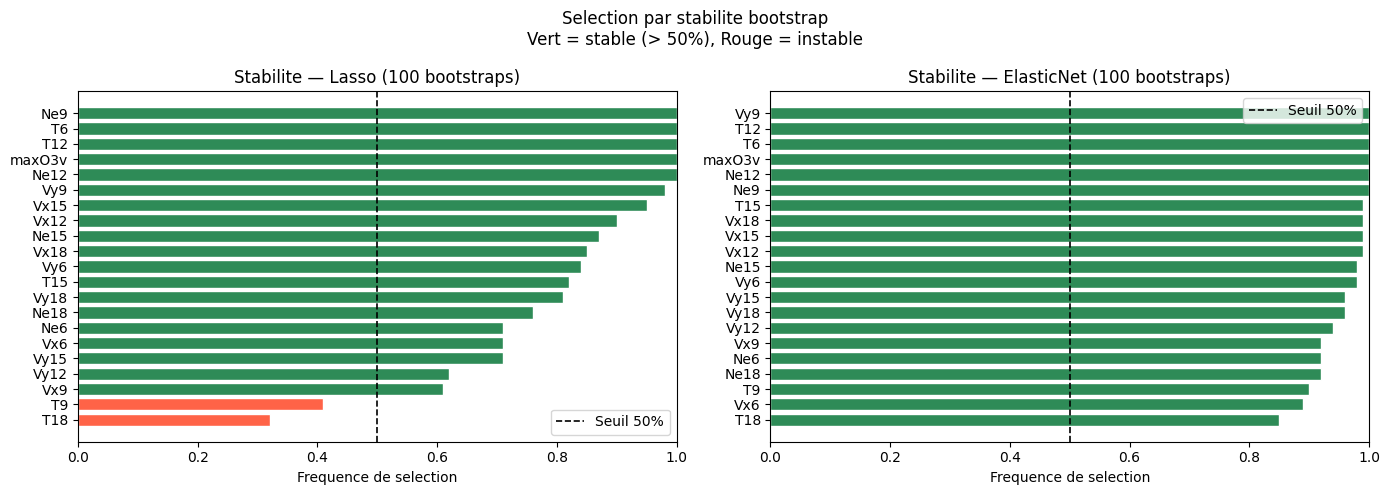

In [8]:
# Visualisation cote a cote : Lasso vs ElasticNet
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for ax, freq, titre in [
    (ax1, freq_lasso, f"Lasso ({N_BOOT} bootstraps)"),
    (ax2, freq_enet,  f"ElasticNet ({N_BOOT} bootstraps)")
]:
    freq_s = freq.sort_values(ascending=True)
    couleurs = ["seagreen" if f >= 0.5 else "tomato" for f in freq_s]
    ax.barh(freq_s.index, freq_s.values, color=couleurs, edgecolor="white")
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1.2, label="Seuil 50%")
    ax.set_xlabel("Frequence de selection")
    ax.set_title(f"Stabilite — {titre}")
    ax.set_xlim([0, 1])
    ax.legend()

plt.suptitle("Selection par stabilite bootstrap\nVert = stable (> 50%), Rouge = instable", fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# Variables robustes : stables dans Lasso ET ElasticNet
robustes = stab_df[stab_df.stable_les_deux == 1].index.tolist()
print(f"Variables robustes (stables Lasso ET ElasticNet, {N_BOOT} bootstraps) :")
for v in robustes:
    print(f"  {v:20s}  Lasso={freq_lasso[v]:.0%}  ENet={freq_enet[v]:.0%}")

Variables robustes (stables Lasso ET ElasticNet, 100 bootstraps) :
  Ne12                  Lasso=100%  ENet=100%
  Ne9                   Lasso=100%  ENet=100%
  maxO3v                Lasso=100%  ENet=100%
  T6                    Lasso=100%  ENet=100%
  T12                   Lasso=100%  ENet=100%
  Vy9                   Lasso=98%  ENet=100%
  Vx15                  Lasso=95%  ENet=99%
  Vx12                  Lasso=90%  ENet=99%
  Ne15                  Lasso=87%  ENet=98%
  Vx18                  Lasso=85%  ENet=99%
  Vy6                   Lasso=84%  ENet=98%
  T15                   Lasso=82%  ENet=99%
  Vy18                  Lasso=81%  ENet=96%
  Ne18                  Lasso=76%  ENet=92%
  Ne6                   Lasso=71%  ENet=92%
  Vy15                  Lasso=71%  ENet=96%
  Vx6                   Lasso=71%  ENet=89%
  Vy12                  Lasso=62%  ENet=94%
  Vx9                   Lasso=61%  ENet=92%


## 5. Conclusion
Résultats obtenus (validation croisée 10 blocs, 1366 observations, jeu de features `X`) :

**Performances :**
- Meilleure méthode (MSE) : CatBoost (MSE = 154.87, RMSE = 12.4), suivie de la forêt aléatoire (155.28) et du gradient boosting `gbm2` (156.31)
- Jeu de features utilisé : X
- Ecart avec MCO (MSE = 187.51) : −32.6 pts de MSE (≈ −17 %) pour CatBoost ; les méthodes linéaires pénalisées (lasso, elastic, ridge), BIC/AIC, PCR et PLS sont toutes à ≈ 187–188, donc équivalentes aux MCO
- Le boosting/CatBoost et la forêt battent nettement les modèles linéaires : il reste de la non-linéarité/interactions à exploiter. Le stochastic boosting (`gbms1`/`gbms2`, `subsample=0.2`) est un peu moins bon que le boosting classique sur ces données
- BIC (188.23) et AIC (187.74) sont calculés dans `02_Reg_pipeline_complet.ipynb` : ils ne font pas mieux que les MCO complètes

**Variables robustes (sélection par stabilité) :**
- Variables stables Lasso ET ElasticNet : 19 variables sur 21 (dont `T6`, `T12`, `Ne9`, `Ne12`, `maxO3v` à 100 % dans les deux)
- Variables stables dans un seul des deux : `T9` (Lasso 41 % / ENet 90 %) et `T18` (Lasso 32 % / ENet 85 %), stables seulement avec ElasticNet
- Interprétation météorologique : à compléter (températures du matin/midi, nébulosité de la mi-journée et ozone de la veille `maxO3v` ressortent systématiquement)

**Pistes d'amélioration :**
- Tester `ESPACE = "XI"` / `"XIP"` dans le 02 (interactions + polynomes) pour les modèles linéaires, vu l'avantage des méthodes non linéaires
- Régler les hyperparamètres de CatBoost/GBM (profondeur, learning rate) plutôt que de se limiter à l'early stopping
- Augmenter `N_BOOT` (ex. 500) pour des fréquences plus stables
- Modifier le seuil de stabilité (50% → 80%) pour être plus conservateur